# Treinamento HMDA 2024 — recorte integral com os 18 campos válidos

Análise histórica. Requer o Parquet original de 2024. Para novas rodadas, use os notebooks 03 e 04. Esta análise usa todos os pedidos elegíveis que passaram na validação dos 18 campos, com semente 42 e divisão estratificada 70/20/10. Os relatórios ficam em reports/local/full_valid18_702010 no PC e em reports/colab/full_valid18_702010 no Drive.

As comparações por grupo medem disparidades descritivas em pontos percentuais. As simulações mantêm os outros atributos fixos e medem a sensibilidade do modelo à categoria informada. A categoria brasileira parda não tem equivalente direto nos rótulos públicos do HMDA. Raça e etnia são avaliadas em eixos distintos.


Os gráficos perfis_pareados mostram pessoa negra ou indígena em relação à branca, latina em relação à não latina, e setor de renda alta em relação ao de renda baixa. Todos usam os mesmos perfis no modelo completo.

In [7]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.calibration import calibration_curve
from sklearn.metrics import accuracy_score, brier_score_loss, confusion_matrix, precision_recall_fscore_support
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, balanced_accuracy_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import sklearn

try:
    from google.colab import drive
except ImportError:
    ROOT = Path.cwd()
    if ROOT.name == 'notebooks':
        ROOT = ROOT.parent
    REPORTS = ROOT / 'reports/local'
else:
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/hmda-credit-fairness')
    REPORTS = ROOT / 'reports/colab'
DATASET = ROOT / 'data/processed/valid_18/hmda_2024_purchase_valid18.parquet'
SEED = 42
VALIDATION_FRACTION = 0.20
TEST_FRACTION = 0.10
FOREST_TREES = 100
FOREST_JOBS = 1
MIN_GROUP_SIZE_PLOT = 100

if not DATASET.is_file():
    raise FileNotFoundError(f'Parquet original da rodada de 2024 ausente: {DATASET}')
REPORTS = REPORTS / 'full_valid18_702010'
REPORTS.mkdir(parents=True, exist_ok=True)

BASE_NUM = ['income', 'loan_amount', 'loan_term', 'property_value']
BASE_CAT = ['lei', 'activity_year', 'applicant_age', 'debt_to_income_ratio',
            'loan_type', 'lien_status', 'construction_method', 'total_units']
DEMOGRAPHIC = ['derived_race', 'derived_ethnicity']
TRACT_INCOME = 'tract_to_msa_income_percentage'
FEATURES = BASE_NUM + BASE_CAT + DEMOGRAPHIC + [TRACT_INCOME]

FileNotFoundError: Parquet original da rodada de 2024 ausente: c:\Users\cg3034593\Documents\artigo\data\processed\valid_18\hmda_2024_purchase_valid18.parquet

In [ ]:
fields = FEATURES + ['approved']
with pq.ParquetFile(DATASET) as parquet:
    if (parquet.schema_arrow.metadata or {}).get(b'hmda_validated_fields') != b'18':
        raise ValueError('Base sem a marca de validação dos 18 campos. Use o Parquet original da rodada de 2024.')
    total = parquet.metadata.num_rows
    if total < 1:
        raise ValueError('O Parquet precisa conter registros.')
    data = parquet.read(columns=fields).to_pandas(split_blocks=True, self_destruct=True)
if len(data) != total or data.isna().any().any():
    raise ValueError('O Parquet contém inconsistências ou valores ausentes. Verifique o Parquet original da rodada de 2024.')

y = data['approved']
if set(y.unique()) != {0, 1} or y.value_counts().min() < 10:
    raise ValueError('A amostra deve conter pelo menos dez registros de cada classe.')

development, test = train_test_split(
    data.index, test_size=TEST_FRACTION, stratify=y, random_state=SEED,
)
validation_fraction_of_development = VALIDATION_FRACTION / (1 - TEST_FRACTION)
fit, validation = train_test_split(
    development, test_size=validation_fraction_of_development,
    stratify=y.loc[development], random_state=SEED,
)
splits = {'ajuste': fit, 'validacao': validation, 'teste': test}
split_summary = pd.DataFrame([
    {'particao': name, 'n': len(idx), 'aprovados': int(y.loc[idx].sum()),
     'recusados': int(y.loc[idx].eq(0).sum())}
    for name, idx in splits.items()
])
split_summary.to_csv(REPORTS / 'particoes.csv', index=False)
display(split_summary)

,particao,n,aprovados,recusados
0,ajuste,2037448,1799608,237840
1,validacao,582129,514174,67955
2,teste,291065,257088,33977


## Ajuste e escolha do limiar

O pré-processamento é ajustado exclusivamente nos dados de ajuste. A regressão logística padroniza as variáveis numéricas. A codificação one-hot ignora categorias inéditas. Os pedidos já passaram na validação dos 18 campos no preparo. Escolhemos o limiar de aprovação que maximiza a acurácia balanceada na validação. Usamos esse limiar para todos os grupos no teste. A PR-AUC é a área trapezoidal da curva precisão-revocação com recusa como classe positiva.

In [ ]:
configs = {
    'A': (BASE_NUM, BASE_CAT),
    'A+B': (BASE_NUM, BASE_CAT + DEMOGRAPHIC),
    'A+C': (BASE_NUM + [TRACT_INCOME], BASE_CAT),
    'A+B+C': (BASE_NUM + [TRACT_INCOME], BASE_CAT + DEMOGRAPHIC),
}

def build_pipeline(algorithm, numerical, categorical):
    if algorithm == 'Regressão logística':
        numeric_transform = StandardScaler()
        model = LogisticRegression(max_iter=1000, random_state=SEED)
    else:
        numeric_transform = 'passthrough'
        model = RandomForestClassifier(
            n_estimators=FOREST_TREES, max_depth=20, min_samples_leaf=5,
            random_state=SEED, n_jobs=FOREST_JOBS,
        )
    preprocessor = ColumnTransformer(
        [
            ('numeric', numeric_transform, numerical),
            ('categorical', OneHotEncoder(handle_unknown='ignore', min_frequency=10), categorical),
        ],
        sparse_threshold=1.0,
    )
    return Pipeline([('preprocess', preprocessor), ('model', model)])

observed = y.loc[test].to_numpy()
profile_indices = np.random.default_rng(SEED).choice(test, size=min(20_000, len(test)), replace=False)
scenario_rows, calibration_rows = [], []

# Cenários no modelo completo, avaliados nos mesmos perfis de teste.
racas = {
    'Branca': 'White',
    'Negra': 'Black or African American',
    'Indígena (EUA/Alasca)': 'American Indian or Alaska Native',
}
etnias = {'Não latina': 'Not Hispanic or Latino', 'Latina': 'Hispanic or Latino'}
# Valores de renda relativa usados nos cenários de perfis fixos.
rendas = {'Setor de renda baixa': 67.0, 'Setor de renda alta': 143.0}
perfil_rows, contrast_rows = [], []

def evaluate_profiles(pipeline, profiles, algorithm, threshold):
    predictions_by_profile = {}
    for race, race_value in racas.items():
        for ethnicity, ethnicity_value in etnias.items():
            for area, income in rendas.items():
                changed = profiles.assign(derived_race=race_value, derived_ethnicity=ethnicity_value,
                                          **{TRACT_INCOME: income})
                probability = pipeline.predict_proba(changed)[:, 1]
                approved = probability >= threshold
                key = (race, ethnicity, area)
                predictions_by_profile[key] = (probability, approved)
                perfil_rows.append({
                    'algoritmo': algorithm, 'raca': race, 'etnia': ethnicity, 'setor': area,
                    'renda_relativa_pct': income, 'n_perfis': len(profiles),
                    'probabilidade_media_aprovacao_pct': 100 * probability.mean(),
                    'aprovacoes_previstas_pct': 100 * approved.mean(),
                    'recusas_previstas_pct': 100 * (~approved).mean(),
                })

    low, high = rendas
    baseline = ('Branca', 'Não latina', low)
    for key, (p, predicted) in predictions_by_profile.items():
        race, ethnicity, area = key
        comparisons = []
        if race != 'Branca':
            comparisons.append(('Raça', ('Branca', ethnicity, area)))
        if ethnicity == 'Latina':
            comparisons.append(('Etnia', (race, 'Não latina', area)))
        if area == high:
            comparisons.append(('Renda do setor', (race, ethnicity, low)))
        if key != baseline:
            comparisons.append(('Cenário combinado', baseline))
        for dimension, reference in comparisons:
            p_ref, ref_prediction = predictions_by_profile[reference]
            contrast_rows.append({
                'algoritmo': algorithm, 'comparacao': dimension,
                'raca': race, 'etnia': ethnicity, 'setor': area,
                'referencia_raca': reference[0], 'referencia_etnia': reference[1],
                'referencia_setor': reference[2], 'n_perfis': len(profiles),
                'delta_probabilidade_aprovacao_pp': 100 * (p - p_ref).mean(),
                'delta_aprovacoes_previstas_pp': 100 * (predicted.mean() - ref_prediction.mean()),
                'aprovacao_para_recusa_pct': 100 * (ref_prediction & ~predicted).mean(),
                'recusa_para_aprovacao_pct': 100 * (~ref_prediction & predicted).mean(),
            })
scores, predictions, metrics = {}, {}, []
for algorithm in ['Regressão logística', 'Floresta aleatória']:
    for config, (numerical, categorical) in configs.items():
        print(f'Ajustando {algorithm} | {config}', flush=True)
        columns = numerical + categorical
        pipeline = build_pipeline(algorithm, numerical, categorical)
        pipeline.fit(data.loc[fit, columns], y.loc[fit])
        val_scores = pipeline.predict_proba(data.loc[validation, columns])[:, 1]
        fpr, tpr, thresholds = roc_curve(y.loc[validation], val_scores, drop_intermediate=False)
        # Limiares vêm em ordem decrescente. Em empate, escolhemos o maior limiar finito.
        best = np.argmax(np.where(np.isfinite(thresholds), tpr - fpr, -np.inf))
        threshold = thresholds[best]

        probability = pipeline.predict_proba(data.loc[test, columns])[:, 1]
        predicted = (probability >= threshold).astype('int8')
        precision, recall, _ = precision_recall_curve(1 - observed, 1 - probability)
        scores[algorithm, config] = probability
        predictions[algorithm, config] = predicted
        tn, fp, fn, tp = confusion_matrix(observed, predicted, labels=[0, 1]).ravel()
        fraction, mean_pred = calibration_curve(observed, probability, n_bins=10, strategy='uniform')
        for score, actual in zip(mean_pred, fraction):
            calibration_rows.append({'algoritmo': algorithm, 'configuracao': config,
                                     'probabilidade_media': score, 'frequencia_observada': actual})
        if config in {'A+B', 'A+B+C'}:
            for field, reference, group in [
                ('derived_race', 'White', 'Black or African American'),
                ('derived_ethnicity', 'Not Hispanic or Latino', 'Hispanic or Latino'),
            ]:
                scenario = data.loc[profile_indices, columns].copy()
                scenario[field] = reference
                p_reference = pipeline.predict_proba(scenario)[:, 1]
                scenario[field] = group
                p_group = pipeline.predict_proba(scenario)[:, 1]
                scenario_rows.append({
                    'algoritmo': algorithm, 'configuracao': config,
                    'campo_alterado': field, 'referencia': reference, 'grupo': group,
                    'n_perfis': len(scenario),
                    'diferenca_prob_aprovacao_pp': 100 * (p_group - p_reference).mean(),
                    'diferenca_classificacao_aprovacao_pp': 100 * (
                        (p_group >= threshold).mean() - (p_reference >= threshold).mean()
                    ),
                })
        prec_aprov, recall_aprov, f1_aprov, _ = precision_recall_fscore_support(
            observed, predicted, average='binary', zero_division=0,
        )
        metrics.append({
            'algoritmo': algorithm, 'configuracao': config, 'limiar': threshold,
            'acuracia': accuracy_score(observed, predicted),
            'precisao_aprovacao': prec_aprov, 'recall_aprovacao': recall_aprov, 'f1_aprovacao': f1_aprov,
            'brier': brier_score_loss(observed, probability),
            'vn': tn, 'fp': fp, 'fn': fn, 'vp': tp,
            'roc_auc': roc_auc_score(observed, probability),
            'pr_auc_recusa': auc(recall, precision),
            'acuracia_balanceada': balanced_accuracy_score(observed, predicted),
        })
        if config == 'A+B+C':
            evaluate_profiles(pipeline, data.loc[profile_indices, columns], algorithm, threshold)
        del pipeline

results = pd.DataFrame(metrics)
results.to_csv(REPORTS / 'metricas_gerais.csv', index=False)
display(results.round(4))
pd.DataFrame(calibration_rows).to_csv(REPORTS / 'calibracao.csv', index=False)

Ajustando Regressão logística | A
Ajustando Regressão logística | A+B
Ajustando Regressão logística | A+C
Ajustando Regressão logística | A+B+C
Ajustando Floresta aleatória | A
Ajustando Floresta aleatória | A+B
Ajustando Floresta aleatória | A+C
Ajustando Floresta aleatória | A+B+C


,algoritmo,configuracao,limiar,acuracia,precisao_aprovacao,recall_aprovacao,f1_aprovacao,brier,vn,fp,fn,vp,roc_auc,pr_auc_recusa,acuracia_balanceada
0,Regressão logística,A,0.8817,0.8424,0.9572,0.8601,0.9060,0.0640,24095,9882,35978,221110,0.8611,0.6457,0.7846
1,Regressão logística,A+B,0.8817,0.8423,0.9587,0.8584,0.9058,0.0635,24477,9500,36392,220696,0.8652,0.6512,0.7894
2,Regressão logística,A+C,0.8830,0.8404,0.9577,0.8571,0.9046,0.0639,24256,9721,36744,220344,0.8618,0.6462,0.7855
3,Regressão logística,A+B+C,0.8813,0.8426,0.9586,0.8589,0.9060,0.0635,24450,9527,36274,220814,0.8655,0.6513,0.7893
4,Floresta aleatória,A,0.8907,0.8375,0.9567,0.8548,0.9029,0.0729,24023,9954,37336,219752,0.8505,0.6091,0.7809
5,Floresta aleatória,A+B,0.8870,0.8386,0.9581,0.8546,0.9034,0.0731,24370,9607,37380,219708,0.8555,0.6020,0.7859
6,Floresta aleatória,A+C,0.8829,0.8475,0.9554,0.8679,0.9096,0.0723,23564,10413,33961,223127,0.8515,0.6144,0.7807
7,Floresta aleatória,A+B+C,0.8844,0.8430,0.9571,0.8608,0.9064,0.0726,24062,9915,35775,221313,0.8554,0.6089,0.7845


## Erros por grupo

A classe positiva é aprovação para calcular FPR e FNR. FPR é a proporção de recusas observadas que o modelo classificou como aprovação. FNR é a proporção de aprovações observadas que o modelo classificou como recusa. Quando o denominador é zero, a taxa fica ausente no CSV. As faixas propostas de renda do setor são menor que 50%, de 50% até menos de 80%, de 80% até menos de 120% e 120% ou mais. Os grupos são avaliados separadamente por raça, etnia e faixa de renda.

In [ ]:
test_data = data.loc[test]
income_bands = pd.cut(
    test_data[TRACT_INCOME], [-np.inf, 50, 80, 120, np.inf],
    labels=['<50%', '50–<80%', '80–<120%', '≥120%'], right=False,
)
group_fields = {
    'raça': test_data['derived_race'],
    'etnia': test_data['derived_ethnicity'],
    'renda do setor': income_bands.astype(object),
}

for dimension, field in [('raça', 'derived_race'), ('etnia', 'derived_ethnicity')]:
    group_fields[f'{dimension} × renda'] = (
        test_data[field].fillna('Ausente').astype(str)
        + ' | ' + income_bands.astype(object).fillna('Ausente').astype(str)
    )

group_rows = []
for (algorithm, config), predicted in predictions.items():
    for dimension, labels in group_fields.items():
        groups = labels.fillna('Ausente').to_numpy()
        for group in pd.unique(groups):
            mask = groups == group
            actual, pred = observed[mask], predicted[mask]
            negatives, positives = actual == 0, actual == 1
            n_neg, n_pos = negatives.sum(), positives.sum()
            group_rows.append({
                'algoritmo': algorithm, 'configuracao': config,
                'dimensao': dimension, 'grupo': group, 'n': int(mask.sum()),
                'n_recusados': int(n_neg), 'n_aprovados': int(n_pos),
                'aprovacao_observada': actual.mean(), 'aprovacao_prevista': pred.mean(),
                'fpr': pred[negatives].mean() if n_neg else np.nan,
                'fnr': (1 - pred[positives]).mean() if n_pos else np.nan,
            })

group_results = pd.DataFrame(group_rows)
group_results.to_csv(REPORTS / 'metricas_por_grupo.csv', index=False)
display(group_results.head(12).round(4))

,algoritmo,configuracao,dimensao,grupo,n,n_recusados,n_aprovados,aprovacao_observada,aprovacao_prevista,fpr,fnr
0,Regressão logística,A,raça,White,222842,23491,199351,0.8946,0.8006,0.2871,0.1389
1,Regressão logística,A,raça,Black or African American,30247,6333,23914,0.7906,0.6963,0.2803,0.1935
2,Regressão logística,A,raça,Asian,24301,2407,21894,0.9010,0.8569,0.3868,0.0914
3,Regressão logística,A,raça,Joint,9645,966,8679,0.8998,0.8164,0.2940,0.1255
4,Regressão logística,A,raça,American Indian or Alaska Native,2518,523,1995,0.7923,0.6755,0.1797,0.1945
5,Regressão logística,A,raça,2 or more minority races,870,141,729,0.8379,0.7713,0.2695,0.1317
6,Regressão logística,A,raça,Native Hawaiian or Other Pacific Islander,642,116,526,0.8193,0.7181,0.1379,0.1540
7,Regressão logística,A,etnia,Not Hispanic or Latino,236850,26182,210668,0.8895,0.8066,0.2942,0.1297
8,Regressão logística,A,etnia,Hispanic or Latino,43622,6764,36858,0.8449,0.7190,0.2797,0.2004
9,Regressão logística,A,etnia,Joint,10593,1031,9562,0.9027,0.8094,0.2774,0.1332


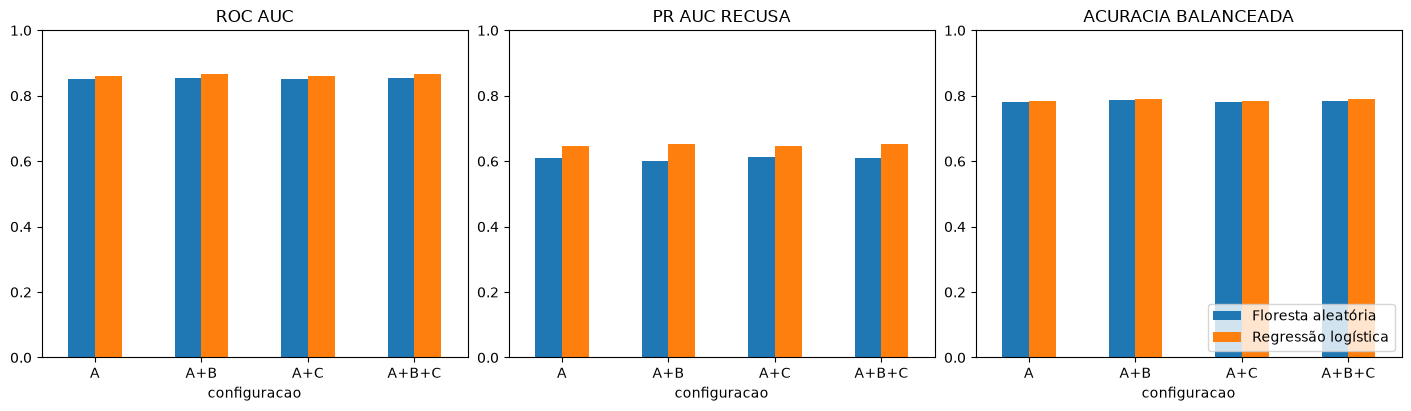

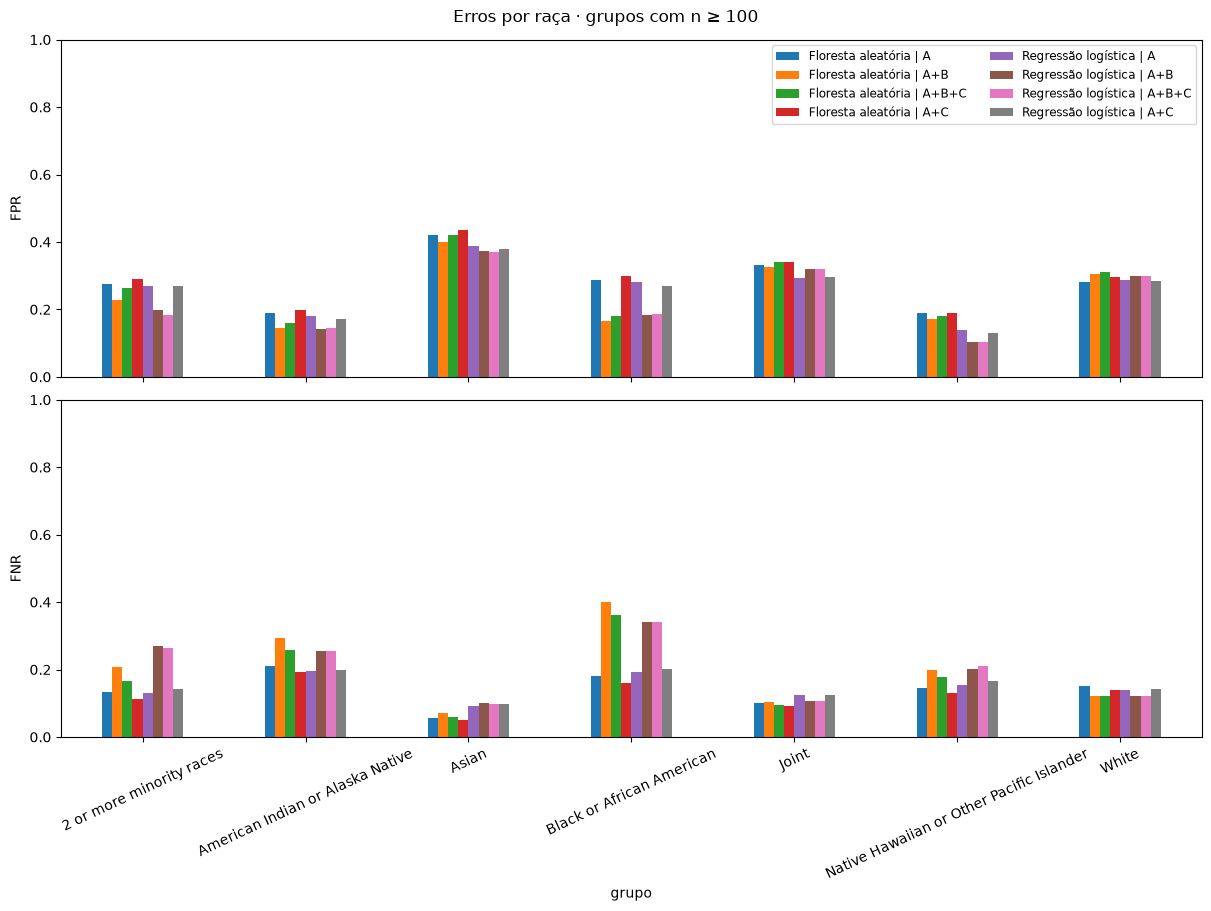

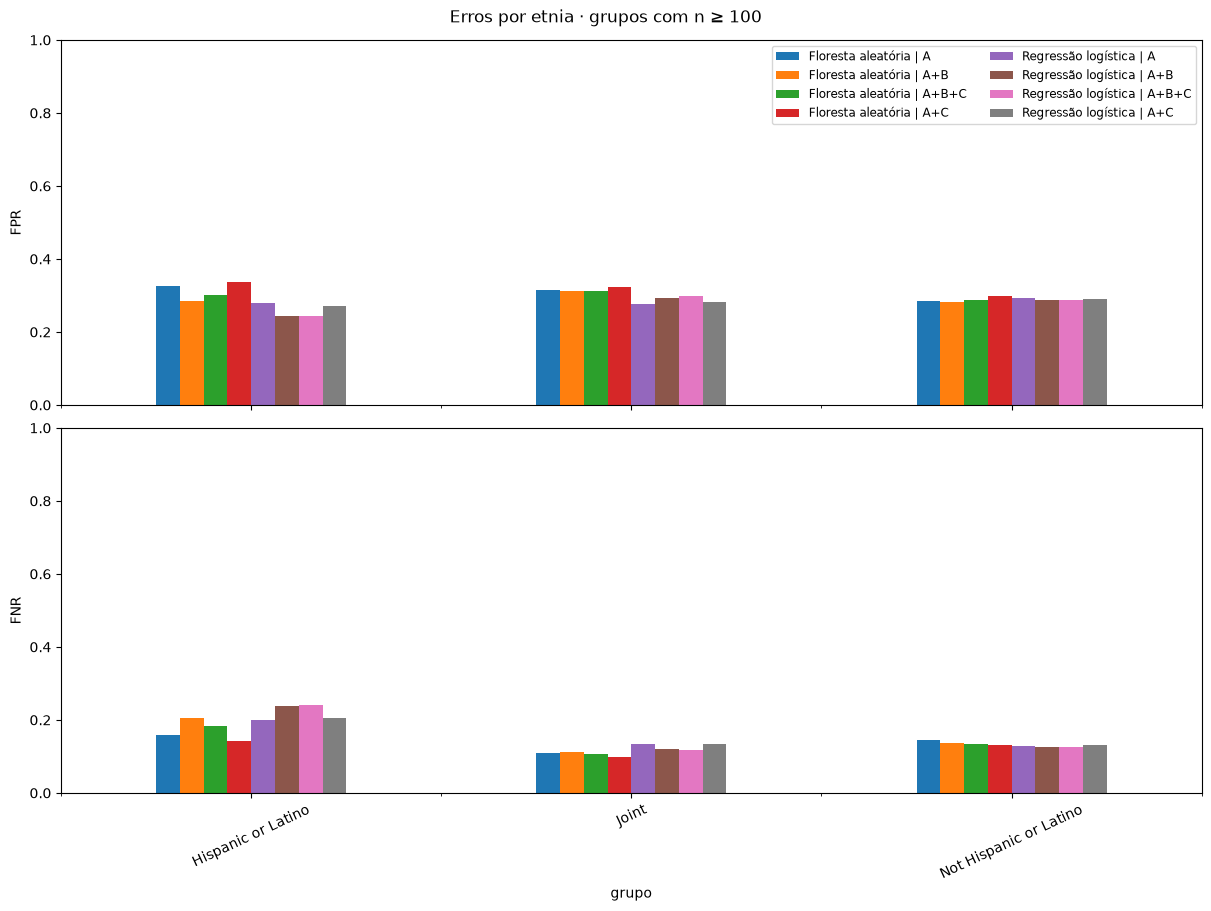

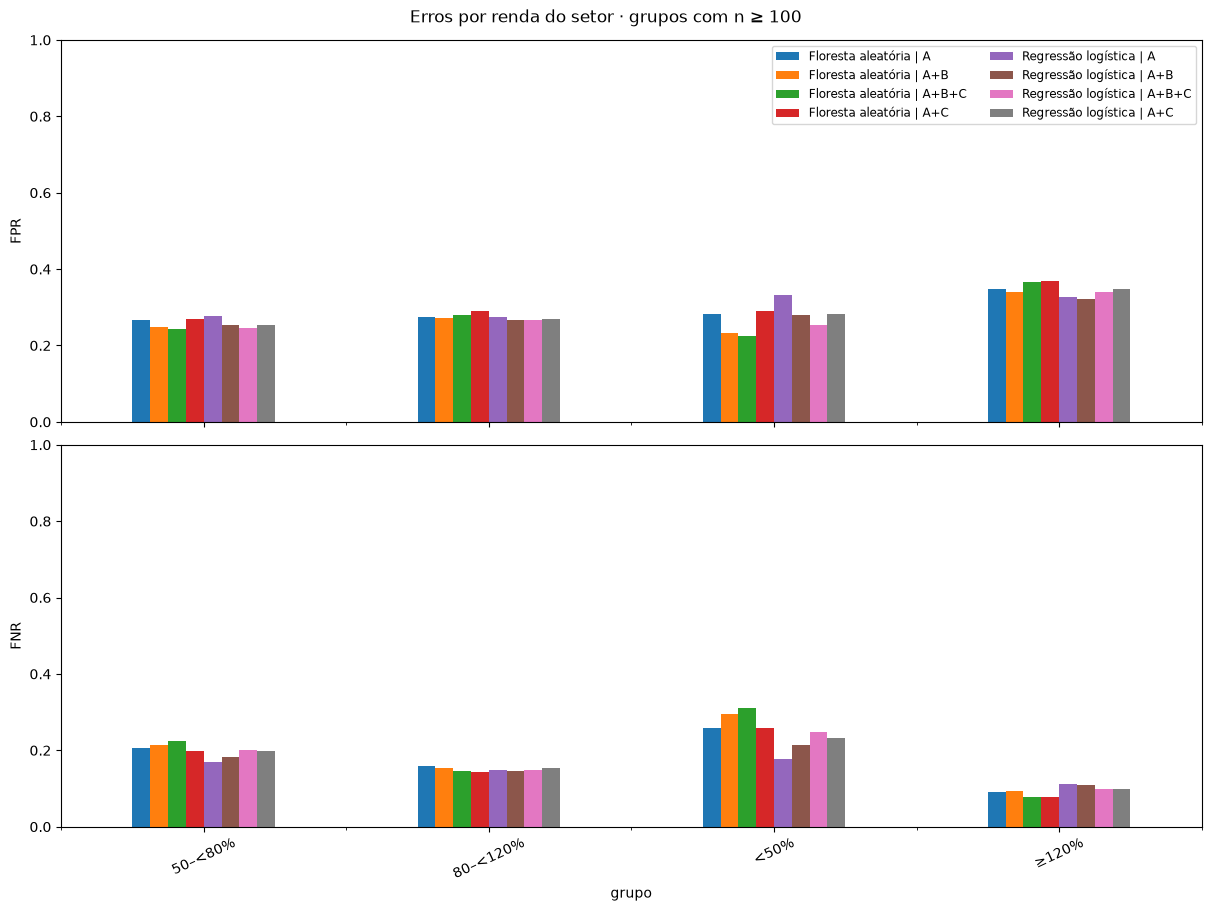

Relatórios em c:\Users\cg3034593\Documents\artigo\reports\local\full_valid18_702010


In [ ]:
chart_metrics = ['roc_auc', 'pr_auc_recusa', 'acuracia_balanceada']
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for metric, axis in zip(chart_metrics, axes):
    wide = results.pivot(index='configuracao', columns='algoritmo', values=metric)
    wide.reindex(configs).plot.bar(ax=axis, ylim=(0, 1), rot=0, legend=False)
    axis.set_title(metric.replace('_', ' ').upper())
axes[-1].legend(loc='lower right')
fig.savefig(REPORTS / 'metricas_gerais.png', dpi=150)
plt.show()

for dimension, subset in group_results.groupby('dimensao', sort=False):
    if ' × ' in dimension:
        continue
    subset = subset.loc[subset['n'].ge(MIN_GROUP_SIZE_PLOT)].copy()
    if subset.empty:
        continue
    subset['modelo'] = subset['algoritmo'] + ' | ' + subset['configuracao']
    fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True, constrained_layout=True)
    for metric, axis in zip(['fpr', 'fnr'], axes):
        wide = subset.pivot(index='grupo', columns='modelo', values=metric)
        wide.plot.bar(ax=axis, ylim=(0, 1), rot=25, legend=False)
        axis.set_ylabel(metric.upper())
    axes[0].legend(ncol=2, fontsize='small')
    fig.suptitle(f'Erros por {dimension} · grupos com n ≥ {MIN_GROUP_SIZE_PLOT}')
    filename = {'raça': 'raca', 'etnia': 'etnia', 'renda do setor': 'renda_setor'}[dimension]
    fig.savefig(REPORTS / f'erros_{filename}.png', dpi=150)
    plt.show()

run_info = {
    'seed': SEED, 'sample_size': len(data),
    'split_fractions': {'ajuste': 0.70, 'validacao': VALIDATION_FRACTION, 'teste': TEST_FRACTION},
    'eligible_rows': total, 'validated_input_fields': 18, 'forest_trees': FOREST_TREES, 'forest_jobs': FOREST_JOBS,
    'minimum_group_size_plot': MIN_GROUP_SIZE_PLOT,
    'sklearn_version': sklearn.__version__, 'pandas_version': pd.__version__,
    'partitions': split_summary.to_dict(orient='records'),
}
print(f'Relatórios em {REPORTS}')

## Disparidades, simulação e exportação para o artigo

Comparamos Black or African American com White e Hispanic or Latino com Not Hispanic or Latino. Valores positivos nas diferenças de recusa indicam taxa mais alta no primeiro grupo. O cruzamento com renda regional pode ser filtrado em metricas_por_grupo.csv. A simulação troca um rótulo por vez em até 20 mil perfis do teste, mantendo as outras entradas fixas. Isso avalia a resposta do modelo, sem estimar o que um banco teria decidido.

,algoritmo,configuracao,dimensao,grupo,referencia,n_grupo,n_referencia,recusa_observada_grupo_pct,recusa_observada_referencia_pct,diferenca_recusa_observada_pp,diferenca_recusa_prevista_pp,diferenca_fpr_pp,diferenca_fnr_pp
0,Regressão logística,A,raça,Black or African American,White,30247,222842,20.94,10.54,10.40,10.43,-0.68,5.46
1,Regressão logística,A,etnia,Hispanic or Latino,Not Hispanic or Latino,43622,236850,15.51,11.05,4.45,8.76,-1.45,7.07
2,Regressão logística,A+B,raça,Black or African American,White,30247,222842,20.94,10.54,10.40,25.71,-11.52,21.85
3,Regressão logística,A+B,etnia,Hispanic or Latino,Not Hispanic or Latino,43622,236850,15.51,11.05,4.45,12.73,-4.29,11.19
4,Regressão logística,A+C,raça,Black or African American,White,30247,222842,20.94,10.54,10.40,11.15,-1.47,6.15
5,Regressão logística,A+C,etnia,Hispanic or Latino,Not Hispanic or Latino,43622,236850,15.51,11.05,4.45,9.08,-1.92,7.35
6,Regressão logística,A+B+C,raça,Black or African American,White,30247,222842,20.94,10.54,10.40,25.80,-11.45,21.99
7,Regressão logística,A+B+C,etnia,Hispanic or Latino,Not Hispanic or Latino,43622,236850,15.51,11.05,4.45,13.06,-4.43,11.55
8,Floresta aleatória,A,raça,Black or African American,White,30247,222842,20.94,10.54,10.40,7.91,0.59,2.73
9,Floresta aleatória,A,etnia,Hispanic or Latino,Not Hispanic or Latino,43622,236850,15.51,11.05,4.45,3.08,4.14,1.39


,algoritmo,configuracao,campo_alterado,referencia,grupo,n_perfis,diferenca_prob_aprovacao_pp,diferenca_classificacao_aprovacao_pp
0,Regressão logística,A+B,derived_race,White,Black or African American,20000,-5.36,-18.15
1,Regressão logística,A+B,derived_ethnicity,Not Hispanic or Latino,Hispanic or Latino,20000,-2.39,-7.44
2,Regressão logística,A+B+C,derived_race,White,Black or African American,20000,-5.17,-17.43
3,Regressão logística,A+B+C,derived_ethnicity,Not Hispanic or Latino,Hispanic or Latino,20000,-2.34,-7.31
4,Floresta aleatória,A+B,derived_race,White,Black or African American,20000,-3.62,-19.32
5,Floresta aleatória,A+B,derived_ethnicity,Not Hispanic or Latino,Hispanic or Latino,20000,-1.92,-7.02
6,Floresta aleatória,A+B+C,derived_race,White,Black or African American,20000,-3.11,-15.64
7,Floresta aleatória,A+B+C,derived_ethnicity,Not Hispanic or Latino,Hispanic or Latino,20000,-1.63,-5.27


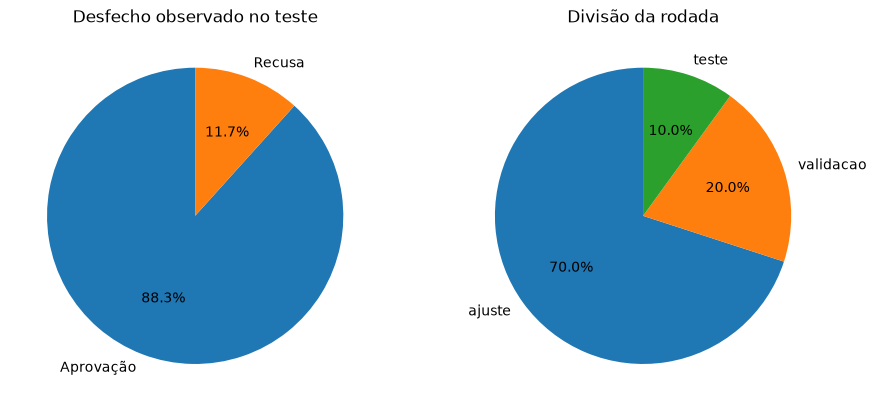

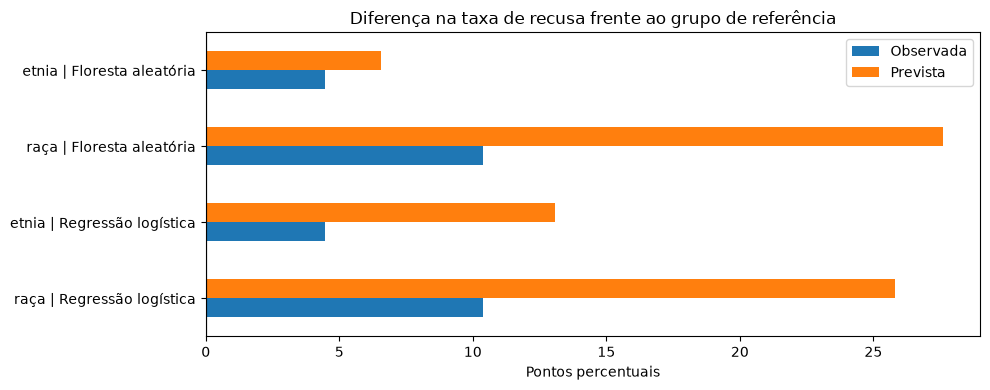

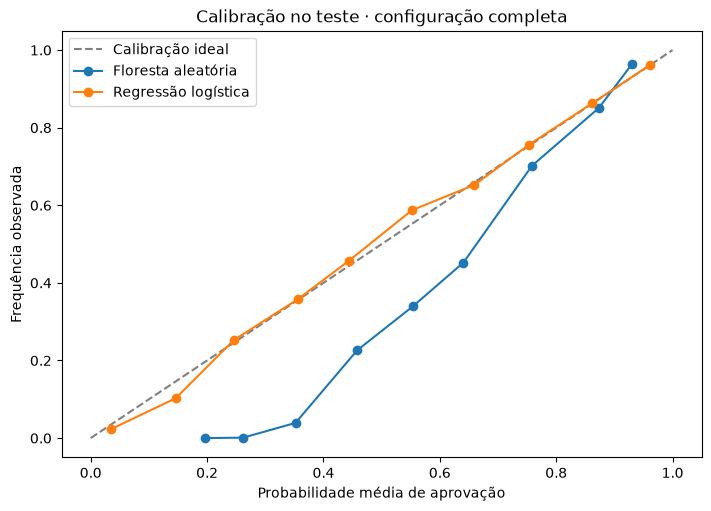

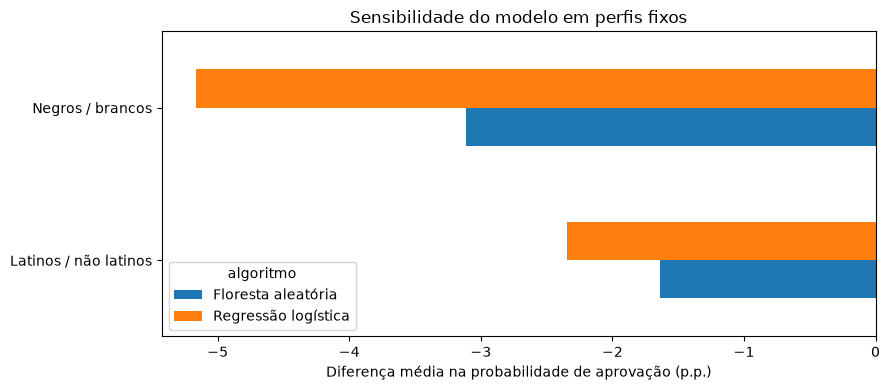

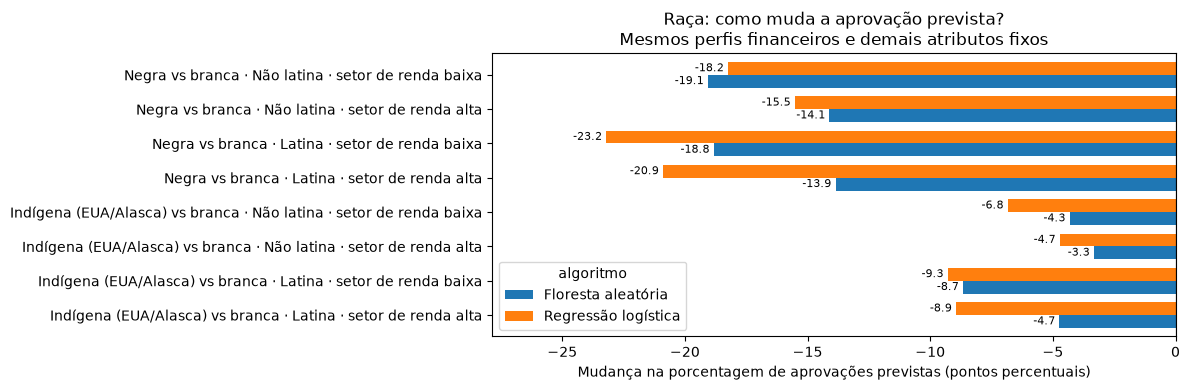

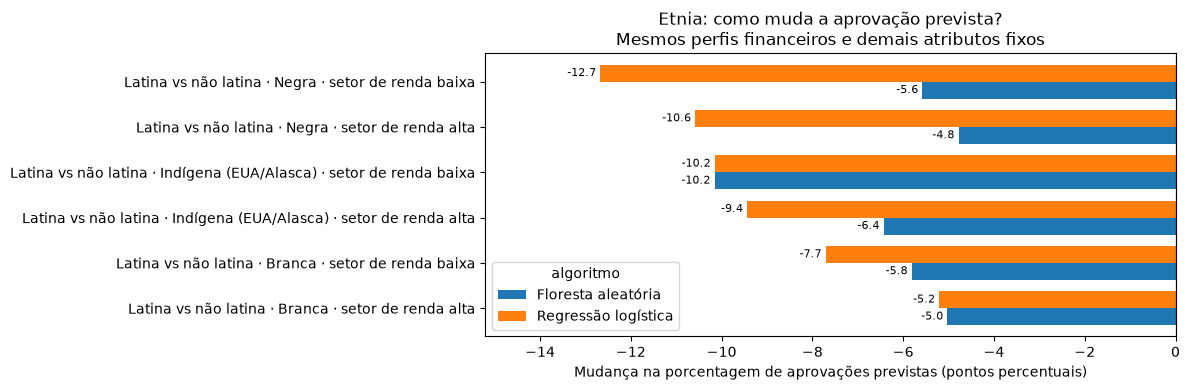

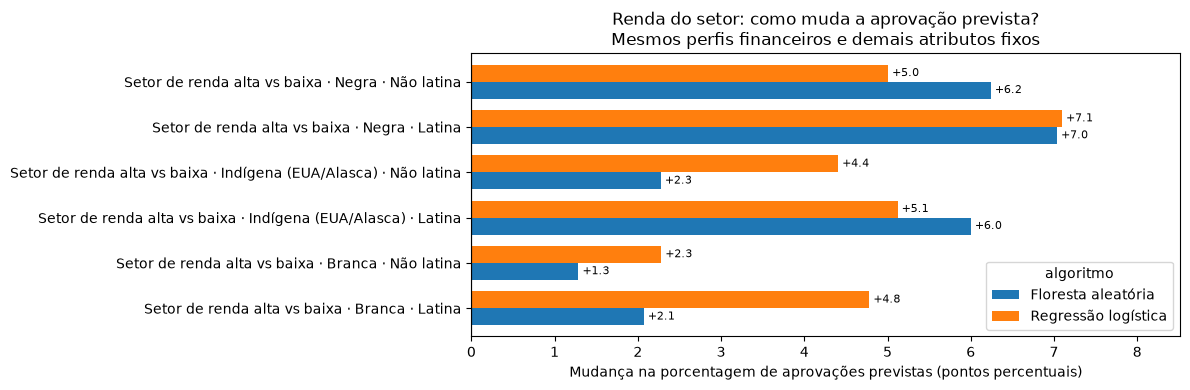

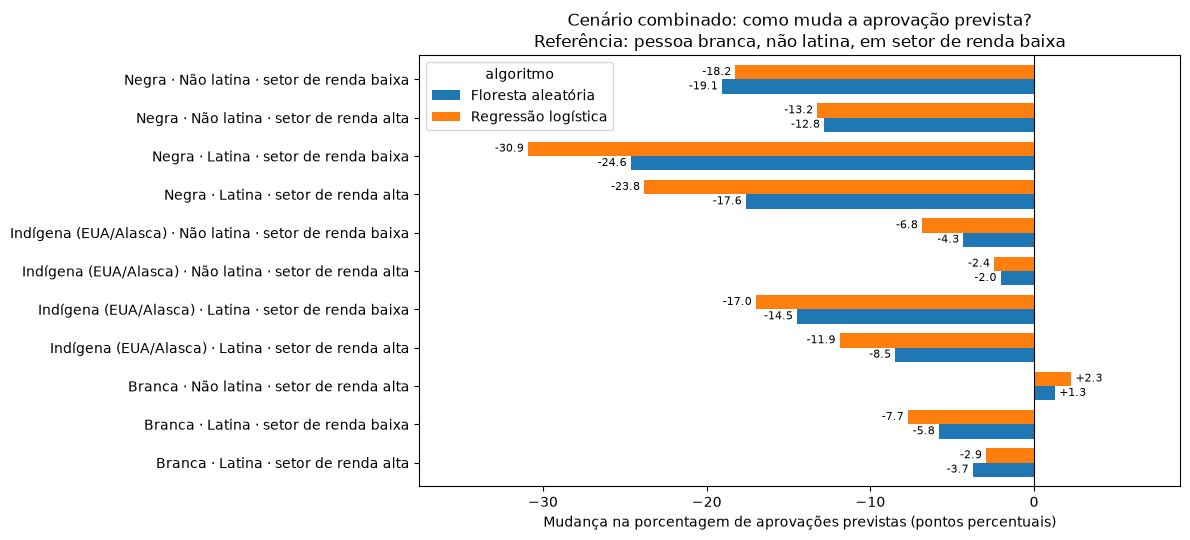

,algoritmo,comparacao,raca,etnia,setor,referencia_raca,referencia_etnia,referencia_setor,n_perfis,delta_probabilidade_aprovacao_pp,delta_aprovacoes_previstas_pp,aprovacao_para_recusa_pct,recusa_para_aprovacao_pct
0,Regressão logística,Renda do setor,Branca,Não latina,Setor de renda alta,Branca,Não latina,Setor de renda baixa,20000,1.04,2.28,0.00,2.28
1,Regressão logística,Cenário combinado,Branca,Não latina,Setor de renda alta,Branca,Não latina,Setor de renda baixa,20000,1.04,2.28,0.00,2.28
2,Regressão logística,Etnia,Branca,Latina,Setor de renda baixa,Branca,Não latina,Setor de renda baixa,20000,-2.33,-7.70,7.70,0.00
3,Regressão logística,Cenário combinado,Branca,Latina,Setor de renda baixa,Branca,Não latina,Setor de renda baixa,20000,-2.33,-7.70,7.70,0.00
4,Regressão logística,Etnia,Branca,Latina,Setor de renda alta,Branca,Não latina,Setor de renda alta,20000,-2.11,-5.21,5.20,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,Floresta aleatória,Cenário combinado,Indígena (EUA/Alasca),Latina,Setor de renda baixa,Branca,Não latina,Setor de renda baixa,20000,-2.96,-14.47,14.47,0.00
58,Floresta aleatória,Raça,Indígena (EUA/Alasca),Latina,Setor de renda alta,Branca,Latina,Setor de renda alta,20000,-0.97,-4.73,4.73,0.00
59,Floresta aleatória,Etnia,Indígena (EUA/Alasca),Latina,Setor de renda alta,Indígena (EUA/Alasca),Não latina,Setor de renda alta,20000,-1.57,-6.43,6.43,0.00
60,Floresta aleatória,Renda do setor,Indígena (EUA/Alasca),Latina,Setor de renda alta,Indígena (EUA/Alasca),Latina,Setor de renda baixa,20000,0.74,6.00,0.09,6.09


,algoritmo,n_perfis,delta_aprovacoes_previstas_pp,contraste
0,Regressão logística,20000,-18.24,Negra vs branca no setor de renda baixa
1,Floresta aleatória,20000,-19.06,Negra vs branca no setor de renda baixa
2,Regressão logística,20000,-6.84,Indígena vs branca no setor de renda baixa
3,Floresta aleatória,20000,-4.32,Indígena vs branca no setor de renda baixa
4,Regressão logística,20000,-7.70,Latina vs não latina no setor de renda baixa
5,Floresta aleatória,20000,-5.81,Latina vs não latina no setor de renda baixa
6,Regressão logística,20000,7.10,Renda alta vs baixa no cenário negro e latino
7,Floresta aleatória,20000,7.03,Renda alta vs baixa no cenário negro e latino
8,Regressão logística,20000,-23.82,Negra e latina no setor de renda alta vs refer...
9,Floresta aleatória,20000,-17.60,Negra e latina no setor de renda alta vs refer...


Relatórios completos em c:\Users\cg3034593\Documents\artigo\reports\local\full_valid18_702010


In [ ]:
# Auditoria descritiva no teste. Raça e etnia são dimensões distintas.
focus = {
    'raça': ('White', 'Black or African American'),
    'etnia': ('Not Hispanic or Latino', 'Hispanic or Latino'),
}
gap_rows = []
for (algorithm, config, dimension), part in group_results.groupby(
    ['algoritmo', 'configuracao', 'dimensao'], sort=False
):
    if dimension not in focus:
        continue
    reference, group = focus[dimension]
    indexed = part.set_index('grupo')
    if not {reference, group}.issubset(indexed.index):
        continue
    ref, target = indexed.loc[reference], indexed.loc[group]
    gap_rows.append({
        'algoritmo': algorithm, 'configuracao': config, 'dimensao': dimension,
        'grupo': group, 'referencia': reference, 'n_grupo': target.n, 'n_referencia': ref.n,
        'recusa_observada_grupo_pct': 100 * (1 - target.aprovacao_observada),
        'recusa_observada_referencia_pct': 100 * (1 - ref.aprovacao_observada),
        'diferenca_recusa_observada_pp': 100 * (ref.aprovacao_observada - target.aprovacao_observada),
        'diferenca_recusa_prevista_pp': 100 * (ref.aprovacao_prevista - target.aprovacao_prevista),
        'diferenca_fpr_pp': 100 * (target.fpr - ref.fpr),
        'diferenca_fnr_pp': 100 * (target.fnr - ref.fnr),
    })
gaps = pd.DataFrame(gap_rows)
gaps.to_csv(REPORTS / 'disparidades_demograficas.csv', index=False)
display(gaps.round(2))

scenarios = pd.DataFrame(scenario_rows)
scenarios.to_csv(REPORTS / 'sensibilidade_perfis_fixos.csv', index=False)
display(scenarios.round(2))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for axis, (name, counts) in zip(axes, [
    ('Desfecho observado no teste', pd.Series({'Aprovação': (observed == 1).sum(), 'Recusa': (observed == 0).sum()})),
    ('Divisão da rodada', split_summary.set_index('particao')['n']),
]):
    axis.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
    axis.set_title(name)
fig.savefig(REPORTS / 'composicao_da_rodada.png', dpi=150)
plt.show()

if not gaps.empty:
    chart = gaps.query("configuracao == 'A+B+C'").copy()
    chart['comparacao'] = chart['dimensao'] + ' | ' + chart['algoritmo']
    axes = chart.set_index('comparacao')[['diferenca_recusa_observada_pp', 'diferenca_recusa_prevista_pp']].rename(columns={
        'diferenca_recusa_observada_pp': 'Observada', 'diferenca_recusa_prevista_pp': 'Prevista',
    }).plot.barh(figsize=(10, 4), title='Diferença na taxa de recusa frente ao grupo de referência')
    axes.set_xlabel('Pontos percentuais')
    axes.set_ylabel('')
    axes.axvline(0, color='black', linewidth=0.8)
    axes.figure.tight_layout()
    axes.figure.savefig(REPORTS / 'disparidades_em_recusas.png', dpi=150)
    plt.show()

# Linhas LaTeX para as tabelas da rodada integral no artigo.
def decimal(value):
    return '%.4f' % value if pd.notna(value) else '--'

def number(value):
    return decimal(value).replace('.', ',')

def latex_rows(frame):
    return '\n'.join(' & '.join(map(str, row)) + r' \\' for row in frame) + '\n'

names = {'Regressão logística': 'Reg. logística', 'Floresta aleatória': 'Floresta'}
table_rows = [
    [names[r.algoritmo], '$' + r.configuracao + '$', number(r.roc_auc),
     number(r.pr_auc_recusa), number(r.acuracia_balanceada)]
    for r in results.itertuples()
]
(REPORTS / 'artigo_metricas_linhas.tex').write_text(latex_rows(table_rows), encoding='utf-8')

summary_rows = []
if not gaps.empty:
    for r in gaps.query("configuracao == 'A+B+C'").itertuples():
        summary_rows.append([
            names[r.algoritmo], 'Negros / brancos' if r.dimensao == 'raça' else 'Latinos / não latinos',
            r.n_grupo, r.n_referencia,
            f'{r.diferenca_recusa_observada_pp:+.2f}'.replace('.', ','),
            f'{r.diferenca_recusa_prevista_pp:+.2f}'.replace('.', ','),
            f'{r.diferenca_fnr_pp:+.2f}'.replace('.', ','),
        ])
if summary_rows:
    (REPORTS / 'artigo_conclusao_linhas.tex').write_text(latex_rows(summary_rows), encoding='utf-8')

calibration = pd.DataFrame(calibration_rows)
fig, axis = plt.subplots(figsize=(7, 5), constrained_layout=True)
axis.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibração ideal')
for algorithm, model in calibration.query("configuracao == 'A+B+C'").groupby('algoritmo'):
    axis.plot(model.probabilidade_media, model.frequencia_observada, marker='o', label=algorithm)
axis.set(xlabel='Probabilidade média de aprovação', ylabel='Frequência observada',
         title='Calibração no teste · configuração completa')
axis.legend()
fig.savefig(REPORTS / 'calibracao.png', dpi=150)
plt.show()

if not scenarios.empty:
    complete = scenarios.query("configuracao == 'A+B+C'").copy()
    complete['contraste'] = complete['campo_alterado'].map({
        'derived_race': 'Negros / brancos', 'derived_ethnicity': 'Latinos / não latinos',
    })
    chart = complete.pivot(index='contraste', columns='algoritmo',
                           values='diferenca_prob_aprovacao_pp')
    axis = chart.plot.barh(figsize=(9, 4), title='Sensibilidade do modelo em perfis fixos')
    axis.set_xlabel('Diferença média na probabilidade de aprovação (p.p.)')
    axis.set_ylabel('')
    axis.figure.tight_layout()
    axis.figure.savefig(REPORTS / 'sensibilidade_perfis_fixos.png', dpi=150)
    plt.show()

profiles_summary = pd.DataFrame(perfil_rows)
contrasts = pd.DataFrame(contrast_rows)
profiles_summary.to_csv(REPORTS / 'perfis_pareados_cenarios.csv', index=False)
contrasts.to_csv(REPORTS / 'perfis_pareados_diferencas.csv', index=False)

def readable_contrast(row):
    if row.comparacao == 'Raça':
        return f'{row.raca} vs branca · {row.etnia} · {row.setor.lower()}'
    if row.comparacao == 'Etnia':
        return f'Latina vs não latina · {row.raca} · {row.setor.lower()}'
    if row.comparacao == 'Renda do setor':
        return f'Setor de renda alta vs baixa · {row.raca} · {row.etnia}'
    return f'{row.raca} · {row.etnia} · {row.setor.lower()}'

for dimension, filename in [
    ('Raça', 'raca'), ('Etnia', 'etnia'), ('Renda do setor', 'renda'),
    ('Cenário combinado', 'combinado'),
]:
    chart = contrasts.loc[contrasts['comparacao'].eq(dimension)].copy()
    chart['cenário'] = chart.apply(readable_contrast, axis=1)
    wide = chart.pivot(index='cenário', columns='algoritmo', values='delta_aprovacoes_previstas_pp')
    axis = wide.plot.barh(figsize=(12, max(4, len(wide) * 0.5)), width=0.75)
    axis.axvline(0, color='black', linewidth=0.8)
    axis.set_xlabel('Mudança na porcentagem de aprovações previstas (pontos percentuais)')
    axis.set_ylabel('')
    subtitle = ('Referência: pessoa branca, não latina, em setor de renda baixa'
                if dimension == 'Cenário combinado' else 'Mesmos perfis financeiros e demais atributos fixos')
    axis.set_title(f'{dimension}: como muda a aprovação prevista?\n{subtitle}')
    for container in axis.containers:
        axis.bar_label(container, fmt='%+.1f', padding=3, fontsize=8)
    axis.margins(x=0.2)
    axis.figure.tight_layout()
    axis.figure.savefig(REPORTS / f'perfis_pareados_{filename}.png', dpi=150)
    plt.show()

display(contrasts.round(2))

# Resumo para o artigo e a apresentação.
low, high = rendas
reference = ('Branca', 'Não latina', low)
selected = {
    'Negra vs branca no setor de renda baixa':
        ('Raça', ('Negra', 'Não latina', low), reference),
    'Indígena vs branca no setor de renda baixa':
        ('Raça', ('Indígena (EUA/Alasca)', 'Não latina', low), reference),
    'Latina vs não latina no setor de renda baixa':
        ('Etnia', ('Branca', 'Latina', low), reference),
    'Renda alta vs baixa no cenário negro e latino':
        ('Renda do setor', ('Negra', 'Latina', high), ('Negra', 'Latina', low)),
    'Negra e latina no setor de renda alta vs referência':
        ('Cenário combinado', ('Negra', 'Latina', high), reference),
}
pairs = ['raca', 'etnia', 'setor']
ref_pairs = ['referencia_raca', 'referencia_etnia', 'referencia_setor']
delta_field = 'delta_aprovacoes_previstas_pp'

def presentation_summary(frame):
    rows = []
    for title, (dimension, case, ref) in selected.items():
        match = frame['comparacao'].eq(dimension)
        for name, value in zip(pairs + ref_pairs, case + ref):
            match &= frame[name].eq(value)
        rows.append(frame.loc[match, ['algoritmo', 'n_perfis', delta_field]].assign(contraste=title))
    return pd.concat(rows, ignore_index=True)

summary = presentation_summary(contrasts)
summary.to_csv(REPORTS / 'perfis_pareados_resumo_apresentacao.csv', index=False)
display(summary.round(2))

article_lines = []
case_names = {
    'Negra vs branca no setor de renda baixa': 'a troca de branca para negra',
    'Indígena vs branca no setor de renda baixa': 'a troca de branca para indígena dos EUA/Alasca',
    'Latina vs não latina no setor de renda baixa': 'a troca de etnia não latina para latina',
    'Renda alta vs baixa no cenário negro e latino': 'a troca para setor de renda alta no cenário negro e latino',
    'Negra e latina no setor de renda alta vs referência': 'o cenário negro e latino de renda alta em relação à referência',
}
def pp(value):
    return f'{value:+.2f}'.replace('.', ',')

for title, rows in summary.groupby('contraste', sort=False):
    values = rows.set_index('algoritmo')[delta_field]
    article_lines.append(
        f'Para {case_names[title]}, a diferença nas aprovações previstas foi de '
        f'{pp(values["Regressão logística"])} pontos percentuais na regressão logística '
        f'e {pp(values["Floresta aleatória"])} na floresta aleatória.'
    )
n_total = f'{len(data):,}'.replace(',', '.')
n_profiles = f'{len(profile_indices):,}'.replace(',', '.')
latex_text = (
    f'Na rodada com {n_total} solicitações, repetimos a simulação em '
    f'{n_profiles} perfis de teste.' + '\n\n'
    + '\n\n'.join(article_lines) + '\n'
)
(REPORTS / 'artigo_perfis_fixos_integral.tex').write_text(latex_text, encoding='utf-8')

(REPORTS / 'execucao.json').write_text(json.dumps(run_info, indent=2), encoding='utf-8')
print(f'Relatórios completos em {REPORTS}')